# Step 7 — Diagnostics, error analysis and insights

Where the model helps and why: segment analysis, behavioural insights, SHAP, tower attention and feature-group ablations.

### Setup (run first)

**On Google Colab:** *Runtime → Change runtime type → GPU* (T4 is enough; A100/L4 is faster). Put the two raw JDsearch
files in `MyDrive/bt4222/raw/` (`user_behavior_data.txt`, `product_meta_data.txt`). The cell mounts Drive, clones the
repository, installs the requirements and writes every output to `MyDrive/bt4222/outputs/`, so results persist between
sessions and the notebooks can be run one after another (or on different days).

**Locally:** run the notebook from the repository with the virtual environment active; data is read from `data/raw/`
and outputs go to `outputs/`.

`CONFIG = "configs/smoke.yaml"` runs everything on a 2,000-user sample with tiny models (minutes, CPU) to check the code;
`configs/default.yaml` is the real run. Every stage skips work whose outputs already exist; pass `"--force"` to redo one.

In [1]:
import os, subprocess, sys
from pathlib import Path

CONFIG = "configs/default.yaml"          # "configs/smoke.yaml" for a quick check
REPO_URL = "https://github.com/clarequek/bt4222-two-tower-recsys.git"
DRIVE_DIR = "/content/drive/MyDrive/bt4222"   # Colab: raw/ (input) and outputs/ (written by the pipeline)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/bt4222-two-tower-recsys")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    else:
        subprocess.run(["git", "-C", str(ROOT), "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

from jds.notebook import Runner, banner
run = Runner(CONFIG, drive_dir=DRIVE_DIR if IN_COLAB else None)

config configs/default.yaml | scope full | raw data /home/ubuntu/bt4222-two-tower-recsys/data/raw | outputs /home/ubuntu/bt4222-two-tower-recsys/outputs/full


## 7.1 Run (`scripts/07_diagnostics.py`, `src/jds/diagnostics.py`)

Each part below is one function in `diagnostics.py`.

* **`segments`** — test metrics by user activity in the click window, history length, query frequency and length, whether the positives are cold items, and the deepest label; ranker vs two-tower vs popularity vs the prior team's model. `segment_table` assigns each test user to one group per dimension, and metrics are averaged per group. This shows who benefits, which an overall average hides.
* **`insights`** — lift of behavioural signals (open carts, repurchase, recent clicks, brand/shop loyalty, similar past queries, cold items) on engagement in the test session. For each signal: `pos_lift` = positive rate of displayed items with the signal / rate without it, plus the share of all positives and orders the signal covers. The labels are only described here, never used as features, and lift is an association, not a causal effect.
* **`shap`** — exact TreeSHAP contributions of the ranker, by feature and feature group. LightGBM's `pred_contrib` returns one contribution per feature plus the expected value (dropped) for a sample of up to 50,000 test rows. Importance is mean |SHAP| per feature, summed per group with the prefixes in `GROUPS`.
* **`attention`** — how much of the tower's candidate-aware attention goes to short-window events rather than the null slot, on up to 4,096 test users. Only the short window is attended; mid and long are summarised by per-type counts. Null-slot attention is averaged over each slate's real candidates, and the reported share is 1 minus that average, for users with short-window events.
* **`ablations`** (optional, ~1 h) — rankers retrained without one feature group at a time, all on the same 30% of training users and compared with an all-features ranker on those users. The metric drop estimates what the group adds beyond the others; overlapping groups can each show a small drop.

In [2]:
run.stage("07_diagnostics.py", "--parts", "attention,segments,insights,shap")

$ /home/ubuntu/bt4222-two-tower-recsys/.venv/bin/python -u scripts/07_diagnostics.py --config configs/default.yaml --parts attention,segments,insights,shap


06:19:06 diagnostics | tower attention by history segment: {'short': {'share_users_with_events': 0.876220703125, 'mean_attention_on_events_when_present': 0.5448208699195274}, 'mid': {'attention': 'none (per-type counts only)'}, 'long': {'attention': 'none (per-type counts only)'}}


06:19:07 diagnostics | segments:


shape: (64, 6)


┌──────────────┬─────────────────────────┬───────────────────┬───────┬──────────┬──────────┐


...

│ (pu…                         ┆        ┆        ┆        ┆   ┆        ┆        ┆        ┆         │


│ two-tower [test]             ┆ 0.205  ┆ 0.1227 ┆ 0.1827 ┆ … ┆ 0.3509 ┆ 0.2689 ┆ 0.7129 ┆ 17174   │


│ two-tower + LambdaRank       ┆ 0.4622 ┆ 0.3182 ┆ 0.4615 ┆ … ┆ 0.7633 ┆ 0.6435 ┆ 0.9245 ┆ 17174   │


│ [test]                       ┆        ┆        ┆        ┆   ┆        ┆        ┆        ┆         │


└──────────────────────────────┴────────┴────────┴────────┴───┴────────┴────────┴────────┴─────────┘


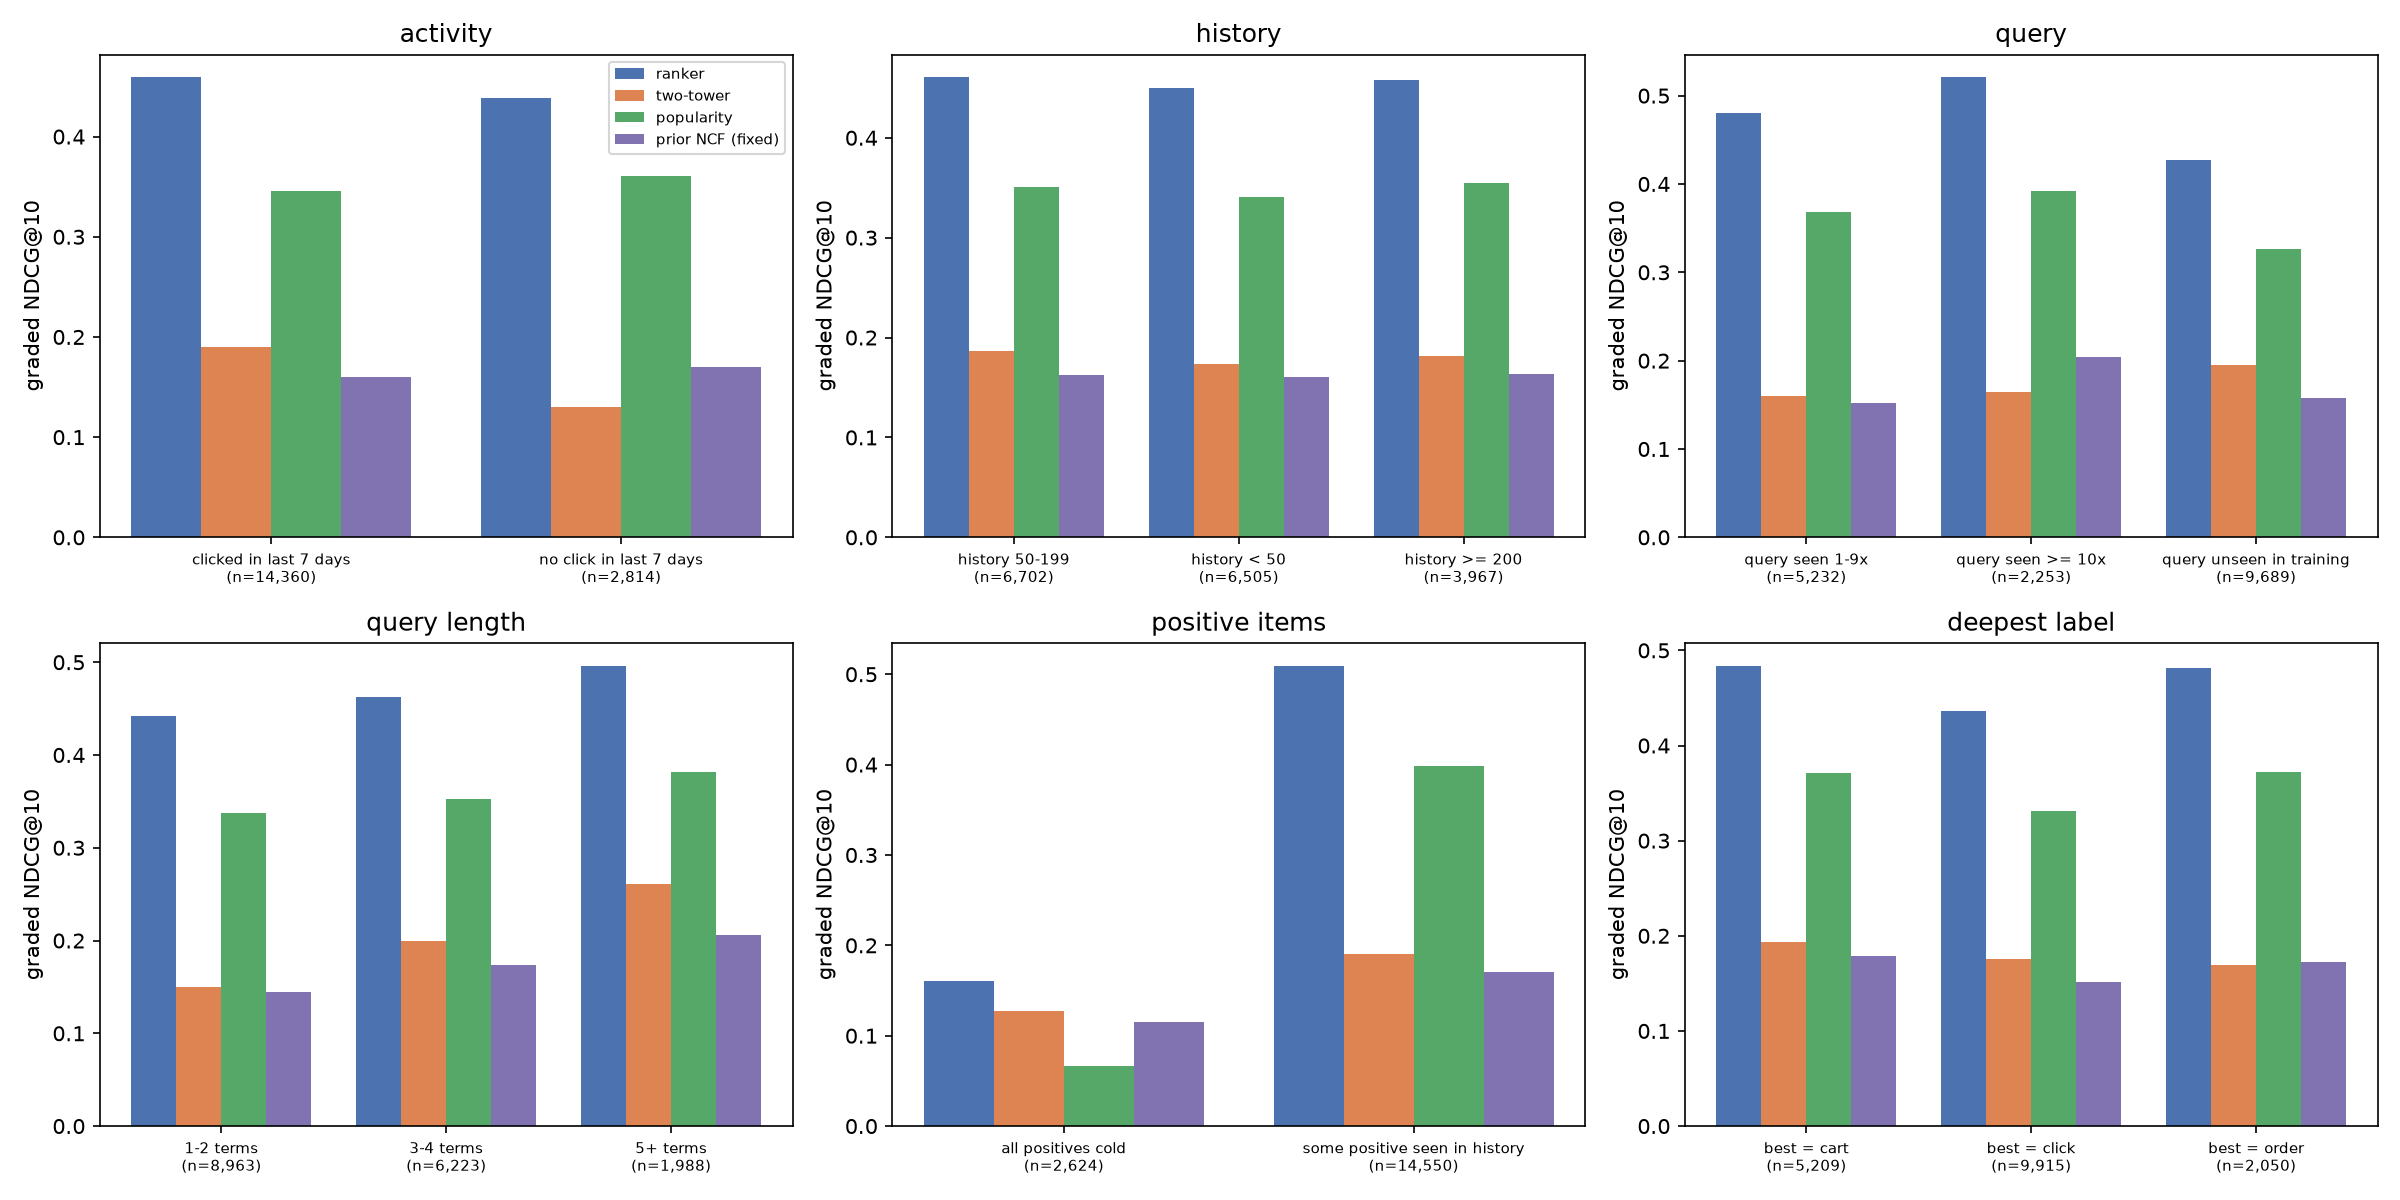

,dimension,segment,model,n,mrr,gndcg10
0,activity,clicked in last 7 days,popularity,14360,0.3407,0.3455
1,activity,clicked in last 7 days,prior NCF (fixed),14360,0.1692,0.1604
2,activity,clicked in last 7 days,ranker,14360,0.4663,0.4590
3,activity,clicked in last 7 days,two-tower,14360,0.2159,0.1901
4,activity,no click in last 7 days,popularity,2814,0.3580,0.3602
5,activity,no click in last 7 days,prior NCF (fixed),2814,0.1785,0.1696
6,activity,no click in last 7 days,ranker,2814,0.4413,0.4386
7,activity,no click in last 7 days,two-tower,2814,0.1492,0.1304
8,deepest_label,best = cart,popularity,5209,0.3841,0.3709
9,deepest_label,best = cart,prior NCF (fixed),5209,0.1991,0.1786


In [3]:
banner()
run.figure("diag_segments.png")
run.table("diag_segments.csv", highlight=("mrr", "gndcg10"))

In [4]:
run.table("diag_insights.csv", highlight=("pos_lift",), caption="Behavioural signals vs engagement in the test session")

,signal,share_of_displayed,pos_rate_with,pos_rate_without,order_rate_with,order_rate_without,share_of_positives,share_of_orders,pos_lift
0,"item carted in last 90 d, not ordered since",0.0031,0.2305,0.0200,0.0180,0.0013,0.0348,0.0418,11.5048
1,item ordered by the user in last 365 d (repurchase),0.0009,0.2707,0.0205,0.0930,0.0013,0.0112,0.0592,13.2200
2,item clicked by the user in last 7 d,0.0056,0.2597,0.0193,0.0170,0.0013,0.0703,0.0710,13.4248
3,brand ordered by the user in last 365 d,0.0576,0.0297,0.0201,0.0041,0.0012,0.0828,0.1766,1.4769
4,shop ordered by the user in last 365 d,0.0171,0.0622,0.0200,0.0116,0.0012,0.0515,0.1484,3.1158
5,category clicked by the user in last 7 d,0.2602,0.0265,0.0187,0.0012,0.0014,0.3328,0.2281,1.4183
6,item engaged under a similar past query,0.0018,0.3252,0.0201,0.0250,0.0013,0.0288,0.0340,16.1526
7,item never in any user's history (cold),0.5654,0.0098,0.0348,0.0003,0.0027,0.2682,0.1253,0.2817


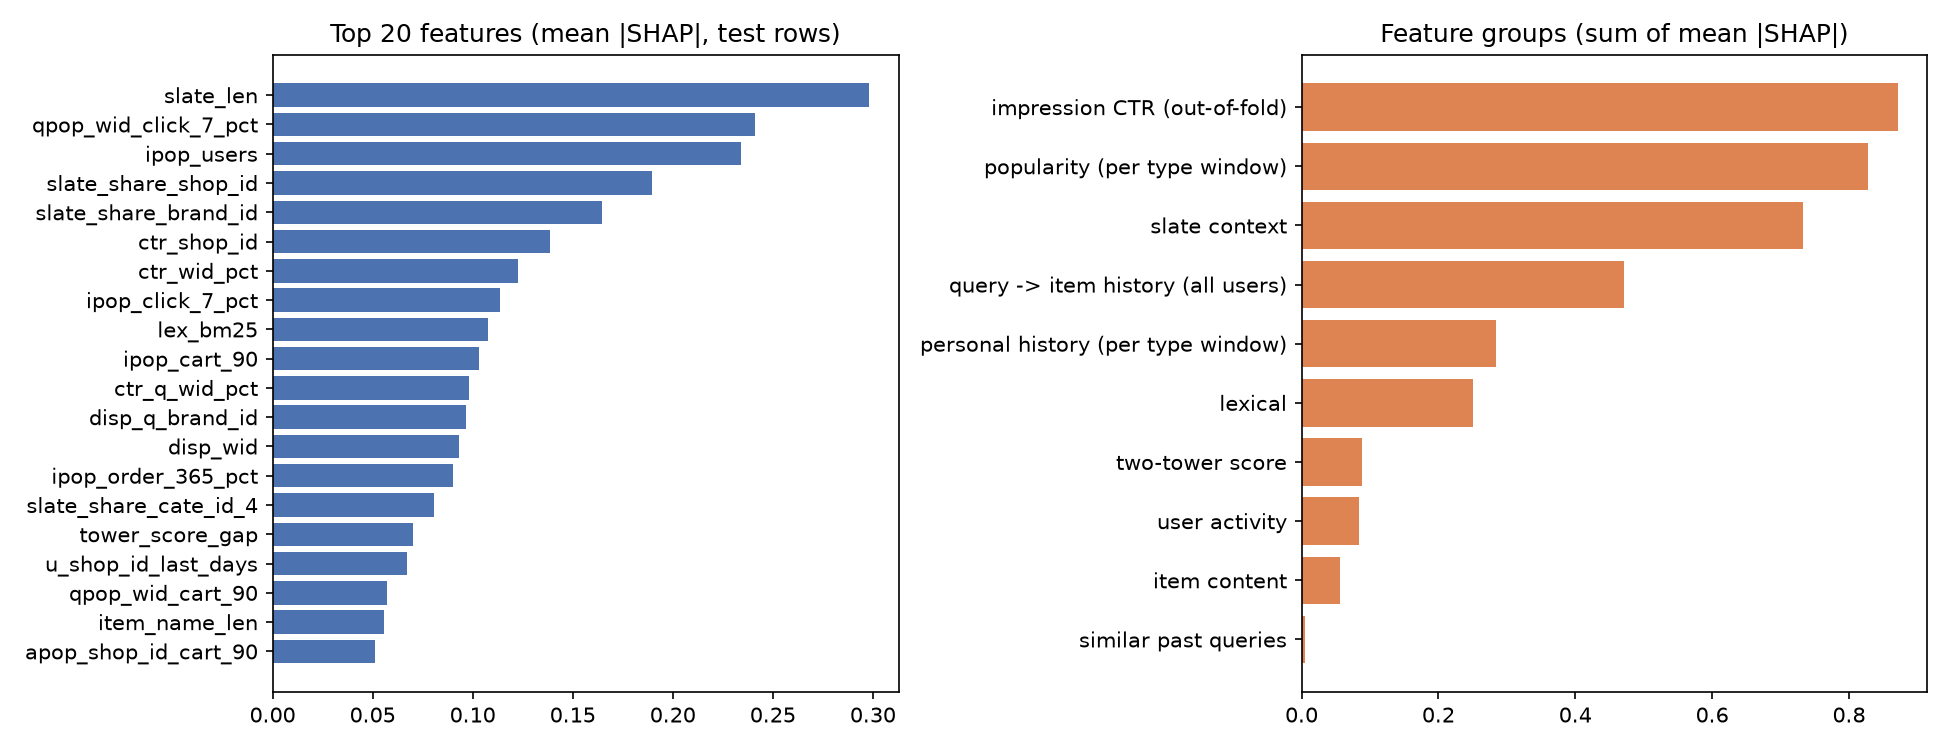

,group,mean_abs_shap
0,impression CTR (out-of-fold),0.8711
1,popularity (per type window),0.8278
2,slate context,0.7324
3,query -> item history (all users),0.4717
4,personal history (per type window),0.2848
5,lexical,0.2507
6,two-tower score,0.0889
7,user activity,0.0832
8,item content,0.0555
9,similar past queries,0.0054


In [5]:
run.figure("diag_shap.png")
run.table("diag_shap_groups.csv", highlight=())

In [6]:
run.json("diag_attention.json")

{'short': {'share_users_with_events': 0.876220703125,
  'mean_attention_on_events_when_present': 0.5448208699195274},
 'mid': {'attention': 'none (per-type counts only)'},
 'long': {'attention': 'none (per-type counts only)'}}

In [7]:
RUN_ABLATIONS = False
if RUN_ABLATIONS:
    run.stage("07_diagnostics.py", "--parts", "ablations")
run.table("diag_ablations.csv", caption="Ranker without one feature group (30% of training users)")

(diag_ablations.csv not produced yet)
